In [7]:
import pybamm
import numpy as np
import matplotlib.pyplot as plt

# 设置随机种子（可复现）
np.random.seed(42)

# 用 PyBaMM 内置的 DFN 模型
# 注意：这里用默认参数（石墨负极 / NMC 正极），后面 Cell 4 做敏感性
model = pybamm.lithium_ion.DFN()

# 实验：1C 放电到截止电压 2.8 V
experiment = pybamm.Experiment([
    "Discharge at 1C until 2.8 V",
])

# 求解器设置
sim = pybamm.Simulation(model, experiment=experiment)
sol = sim.solve()

print(f"求解完成，时间步数: {len(sol['Time [h]'].entries)}")
print(f"最终电压: {sol['Voltage [V]'].entries[-1]:.3f} V")

求解完成，时间步数: 160
最终电压: 2.800 V


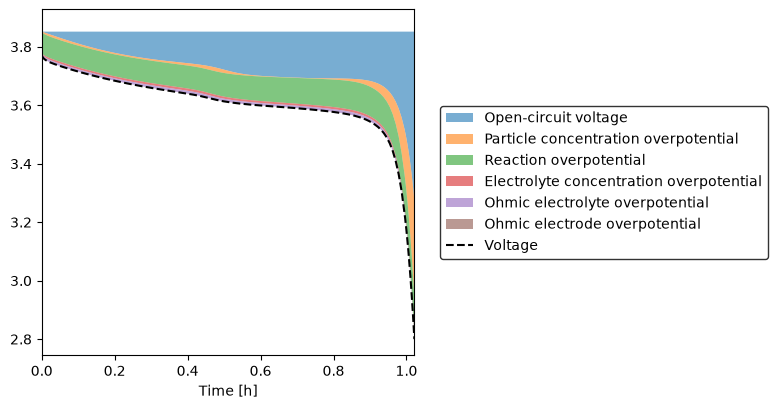

In [8]:
# 方法 A：官方内置函数（最稳，推荐）
sol.plot_voltage_components()
plt.show()

# 方法 B：按正负极拆开看
# sol.plot_voltage_components(split_by_electrode=True)
# plt.show()

c_n shape: (20, 160)
Neg: r_n=(20,), c_n_end=(20,), R_n=5e-06
c_p shape: (20, 160)
Pos: r_p=(20,), c_p_end=(20,), R_p=5e-06
c_e shape: (60, 160)
c_e: x=(60,), c_e_end=(60,), L_total=0.0001
phi_e shape: (60, 160)
phi_e: x2=(60,), phi_e_end=(60,)


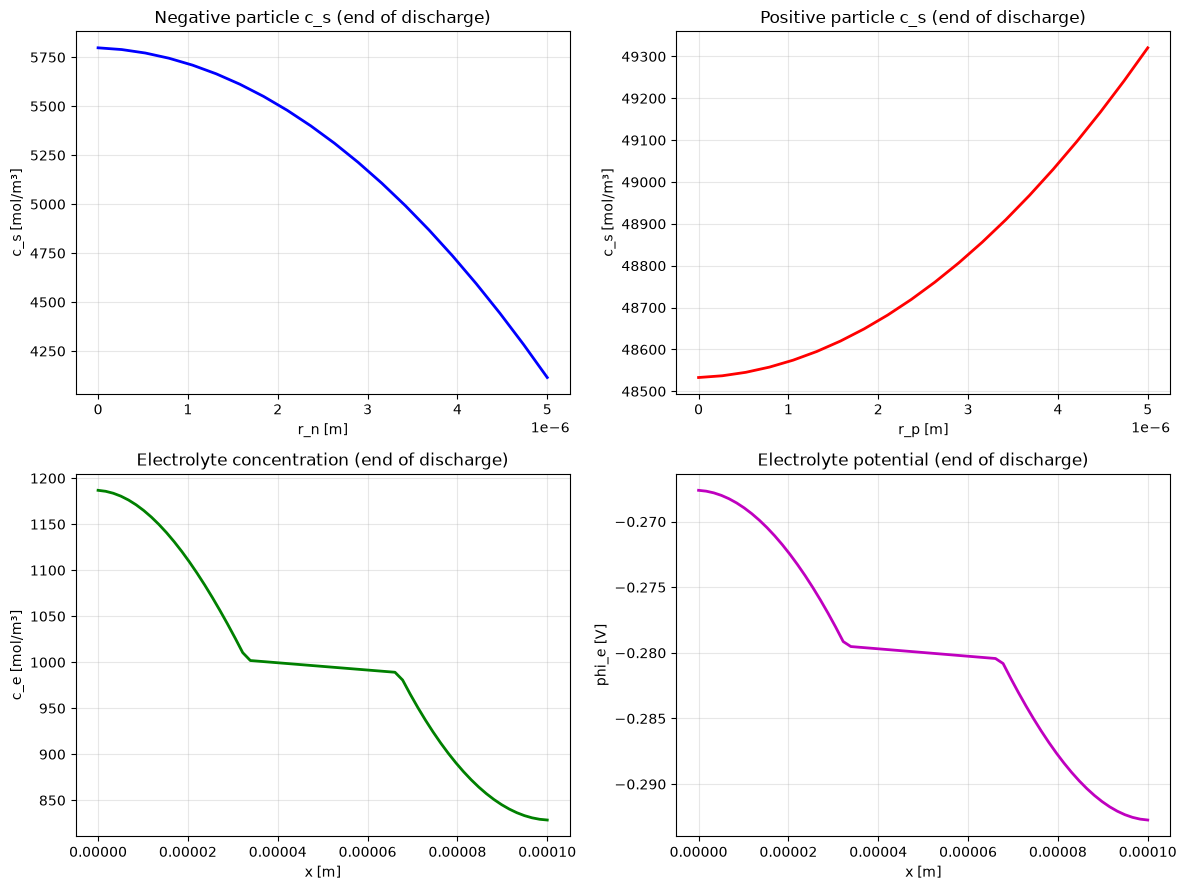

In [10]:
import matplotlib.pyplot as plt
import numpy as np

fig, axs = plt.subplots(2, 2, figsize=(12, 9))

# ========== 图1：负极粒子浓度剖面 ==========
try:
    c_n = np.asarray(sol["X-averaged negative particle concentration [mol.m-3]"].entries)
    print(f"c_n shape: {c_n.shape}")
    
    # c_n 是 (n_r, n_t) = (20, 160)
    # 取最后时间步
    if c_n.ndim == 2:
        c_n_end = c_n[:, -1]
        n_r = c_n.shape[0]
    else:
        c_n_end = c_n
        n_r = len(c_n)
    
    # 手动生成半径坐标：r ∈ [0, R_n]
    # 从模型参数里取粒子半径
    try:
        R_n = param["Negative particle radius [m]"]
    except:
        R_n = 5e-6  # 默认 ~5 μm
    
    r_n = np.linspace(0, R_n, n_r)
    
    axs[0, 0].plot(r_n, c_n_end, "b-", linewidth=2)
    axs[0, 0].set_xlabel("r_n [m]")
    axs[0, 0].set_ylabel("c_s [mol/m³]")
    print(f"Neg: r_n=({n_r},), c_n_end={c_n_end.shape}, R_n={R_n}")
except Exception as e:
    print("Neg FAILED:", e)

axs[0, 0].set_title("Negative particle c_s (end of discharge)")
axs[0, 0].grid(True, alpha=0.3)

# ========== 图2：正极粒子浓度剖面 ==========
try:
    c_p = np.asarray(sol["X-averaged positive particle concentration [mol.m-3]"].entries)
    print(f"c_p shape: {c_p.shape}")
    
    if c_p.ndim == 2:
        c_p_end = c_p[:, -1]
        n_r_p = c_p.shape[0]
    else:
        c_p_end = c_p
        n_r_p = len(c_p)
    
    try:
        R_p = param["Positive particle radius [m]"]
    except:
        R_p = 5e-6
    
    r_p = np.linspace(0, R_p, n_r_p)
    
    axs[0, 1].plot(r_p, c_p_end, "r-", linewidth=2)
    axs[0, 1].set_xlabel("r_p [m]")
    axs[0, 1].set_ylabel("c_s [mol/m³]")
    print(f"Pos: r_p=({n_r_p},), c_p_end={c_p_end.shape}, R_p={R_p}")
except Exception as e:
    print("Pos FAILED:", e)

axs[0, 1].set_title("Positive particle c_s (end of discharge)")
axs[0, 1].grid(True, alpha=0.3)

# ========== 图3：电解质浓度 ==========
try:
    c_e = np.asarray(sol["Electrolyte concentration [mol.m-3]"].entries)
    print(f"c_e shape: {c_e.shape}")
    
    if c_e.ndim == 2:
        c_e_end = c_e[:, -1]
        n_x = c_e.shape[0]
    else:
        c_e_end = c_e
        n_x = len(c_e)
    
    # x 坐标：从 0 到 L = L_n + L_s + L_p
    try:
        L_n = param["Negative electrode thickness [m]"]
        L_s = param["Separator thickness [m]"]
        L_p = param["Positive electrode thickness [m]"]
        L_total = L_n + L_s + L_p
    except:
        L_total = 1e-4  # 默认 ~100 μm
    
    x = np.linspace(0, L_total, n_x)
    
    axs[1, 0].plot(x, c_e_end, "g-", linewidth=2)
    axs[1, 0].set_xlabel("x [m]")
    axs[1, 0].set_ylabel("c_e [mol/m³]")
    print(f"c_e: x=({n_x},), c_e_end={c_e_end.shape}, L_total={L_total}")
except Exception as e:
    print("c_e FAILED:", e)

axs[1, 0].set_title("Electrolyte concentration (end of discharge)")
axs[1, 0].grid(True, alpha=0.3)

# ========== 图4：电解质电势 ==========
try:
    phi_e = np.asarray(sol["Electrolyte potential [V]"].entries)
    print(f"phi_e shape: {phi_e.shape}")
    
    if phi_e.ndim == 2:
        phi_e_end = phi_e[:, -1]
        n_x2 = phi_e.shape[0]
    else:
        phi_e_end = phi_e
        n_x2 = len(phi_e)
    
    x2 = np.linspace(0, L_total, n_x2)
    
    axs[1, 1].plot(x2, phi_e_end, "m-", linewidth=2)
    axs[1, 1].set_xlabel("x [m]")
    axs[1, 1].set_ylabel("phi_e [V]")
    print(f"phi_e: x2=({n_x2},), phi_e_end={phi_e_end.shape}")
except Exception as e:
    print("phi_e FAILED:", e)

axs[1, 1].set_title("Electrolyte potential (end of discharge)")
axs[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

param type: <class 'pybamm.parameters.parameter_values.ParameterValues'>

  Testing 'Negative electrode active material volume fraction' (type=number)
    Original value: 0.6
    Low 0.5: OK, final V = 2.800 V
    High 0.7: OK, final V = 2.800 V

  Testing 'Positive electrode active material volume fraction' (type=number)
    Original value: 0.5
    Low 0.4: OK, final V = 2.800 V
    High 0.6: OK, final V = 2.800 V

  Testing 'Negative particle diffusivity [m2.s-1]' (type=diffusivity)
    Original value: <function graphite_mcmb2528_diffusivity_Dualfoil1998 at 0x000001F88835CF40>
    Low 5e-15: OK, final V = 2.800 V
    High 2e-14: OK, final V = 2.800 V

  Testing 'Positive particle diffusivity [m2.s-1]' (type=diffusivity)
    Original value: <function lico2_diffusivity_Dualfoil1998 at 0x000001F88835EE80>
    Low 5e-15: OK, final V = 2.800 V
    High 2e-14: OK, final V = 2.800 V


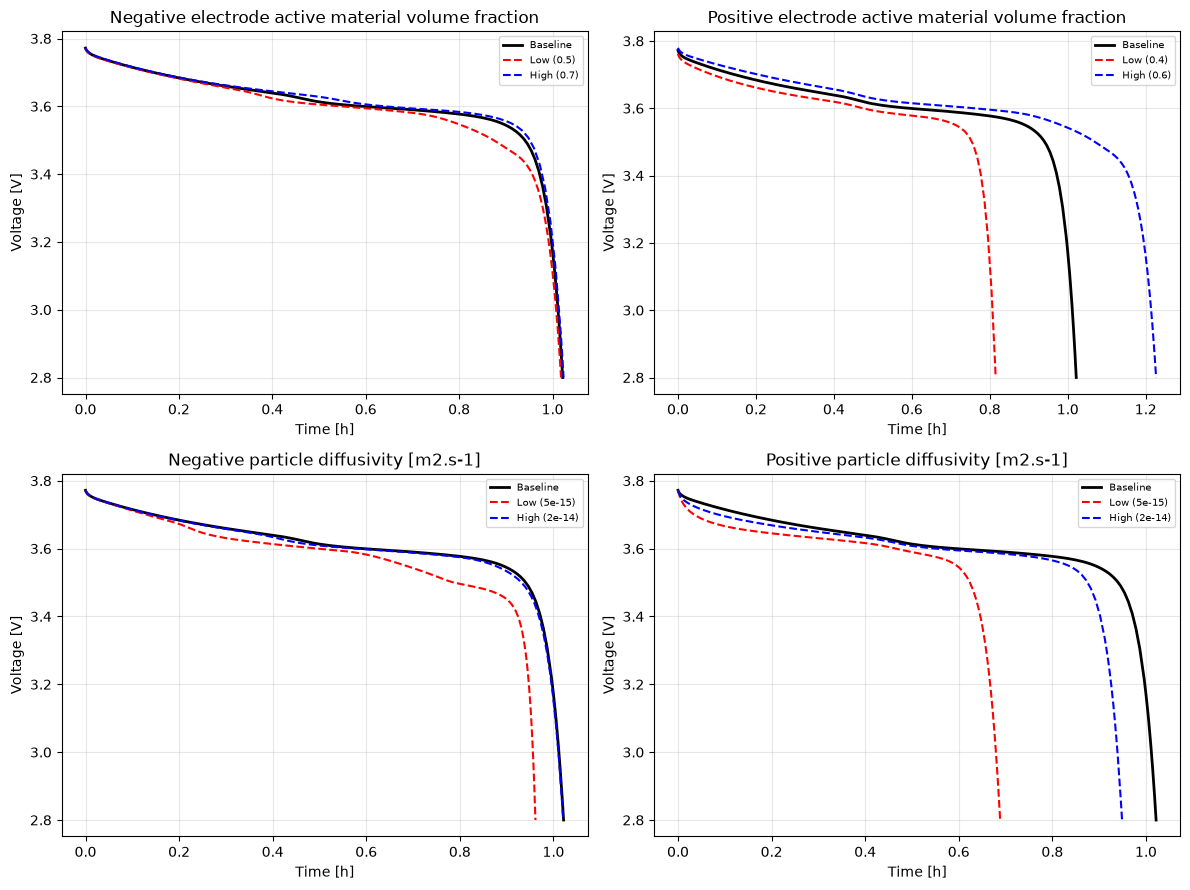


Cell 4 敏感性分析完成


In [13]:
import pybamm
param = pybamm.ParameterValues("Marquis2019")
import numpy as np
import matplotlib.pyplot as plt

# 确认 param 在内存里
print(f"param type: {type(param)}")

# 基准仿真（如果 Cell 1 没跑就跑一次）
if 'sol_base' not in dir():
    sim_base = pybamm.Simulation(model, experiment=experiment)
    sol_base = sim_base.solve()

t_base = sol_base["Time [h]"].entries
V_base = sol_base["Voltage [V]"].entries

# 参数敏感性配置
# 格式: "参数名": (低值, 高值, "类型")
# 类型 "number" = 直接赋值, "diffusivity" = 用常数函数包装
sensitivity_config = {
    "Negative electrode active material volume fraction": (0.5, 0.7, "number"),
    "Positive electrode active material volume fraction": (0.4, 0.6, "number"),
    "Negative particle diffusivity [m2.s-1]": (5e-15, 2e-14, "diffusivity"),
    "Positive particle diffusivity [m2.s-1]": (5e-15, 2e-14, "diffusivity"),
}

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for idx, (param_name, (low, high, ptype)) in enumerate(sensitivity_config.items()):
    ax = axes[idx // 2, idx % 2]
    
    # 检查参数是否存在
    if param_name not in param:
        print(f"  SKIP '{param_name}' — not in param")
        ax.text(0.5, 0.5, f"Param not found:\n{param_name}", 
                ha="center", va="center", transform=ax.transAxes)
        ax.set_title(param_name + " (SKIPPED)")
        continue
    
    print(f"\n  Testing '{param_name}' (type={ptype})")
    print(f"    Original value: {param[param_name]}")
    
    # 基准线
    ax.plot(t_base, V_base, "k", linewidth=2, label="Baseline")
    
    # 低值
    try:
        p_low = param.copy()
        if ptype == "number":
            p_low[param_name] = low
        elif ptype == "diffusivity":
            # 用常数函数包装
            p_low[param_name] = (lambda D: lambda T, c: D)(low)
        
        sim_low = pybamm.Simulation(model, parameter_values=p_low, experiment=experiment)
        sol_low = sim_low.solve()
        ax.plot(sol_low["Time [h]"].entries, sol_low["Voltage [V]"].entries, 
                "r--", linewidth=1.5, label=f"Low ({low})")
        print(f"    Low {low}: OK, final V = {sol_low['Voltage [V]'].entries[-1]:.3f} V")
    except Exception as e:
        print(f"    Low FAILED: {e}")
    
    # 高值
    try:
        p_high = param.copy()
        if ptype == "number":
            p_high[param_name] = high
        elif ptype == "diffusivity":
            p_high[param_name] = (lambda D: lambda T, c: D)(high)
        
        sim_high = pybamm.Simulation(model, parameter_values=p_high, experiment=experiment)
        sol_high = sim_high.solve()
        ax.plot(sol_high["Time [h]"].entries, sol_high["Voltage [V]"].entries, 
                "b--", linewidth=1.5, label=f"High ({high})")
        print(f"    High {high}: OK, final V = {sol_high['Voltage [V]'].entries[-1]:.3f} V")
    except Exception as e:
        print(f"    High FAILED: {e}")
    
    ax.set_xlabel("Time [h]")
    ax.set_ylabel("Voltage [V]")
    ax.set_title(param_name)
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("Cell 4 敏感性分析完成")
print("="*60)

In [14]:
import os
import json
import numpy as np

# ============================================================
# 1. 导出敏感性分析结果到 JSON（方便以后写报告直接读）
# ============================================================
export_dir = "week2_output"
os.makedirs(export_dir, exist_ok=True)

sensitivity_export = {}

for idx, (param_name, (low, high, ptype)) in enumerate(sensitivity_config.items()):
    if param_name not in param:
        sensitivity_export[param_name] = {"status": "SKIPPED", "reason": "not in param"}
        continue
    
    entry = {
        "param_name": param_name,
        "type": ptype,
        "low": low,
        "high": high,
        "baseline_final_V": float(V_base[-1]),
    }
    
    # 尝试导出低值/高值的最终电压
    try:
        p_low = param.copy()
        if ptype == "number":
            p_low[param_name] = low
        elif ptype == "diffusivity":
            p_low[param_name] = (lambda D: lambda T, c: D)(low)
        sim_low = pybamm.Simulation(model, parameter_values=p_low, experiment=experiment)
        sol_low = sim_low.solve()
        entry["low_final_V"] = float(sol_low["Voltage [V]"].entries[-1])
    except Exception as e:
        entry["low_error"] = str(e)
    
    try:
        p_high = param.copy()
        if ptype == "number":
            p_high[param_name] = high
        elif ptype == "diffusivity":
            p_high[param_name] = (lambda D: lambda T, c: D)(high)
        sim_high = pybamm.Simulation(model, parameter_values=p_high, experiment=experiment)
        sol_high = sim_high.solve()
        entry["high_final_V"] = float(sol_high["Voltage [V]"].entries[-1])
    except Exception as e:
        entry["high_error"] = str(e)
    
    sensitivity_export[param_name] = entry
    print(f"  Exported: {param_name}")

# 存 JSON
json_path = os.path.join(export_dir, "sensitivity_results.json")
with open(json_path, "w") as f:
    json.dump(sensitivity_export, f, indent=2)
print(f"\n  Saved → {json_path}")

# ============================================================
# 2. 存 Cell 3 的 4 张剖面图（重新画一遍然后 savefig）
# ============================================================
fig3, axs3 = plt.subplots(2, 2, figsize=(12, 9))

# 图1：负极粒子
r_n = np.linspace(0, param["Negative particle radius [m]"], c_n.shape[0])
axs3[0, 0].plot(r_n, c_n[:, -1], "b-", linewidth=2)
axs3[0, 0].set_xlabel("r_n [m]")
axs3[0, 0].set_ylabel("c_s [mol/m³]")
axs3[0, 0].set_title("Negative particle c_s (end of discharge)")
axs3[0, 0].grid(True, alpha=0.3)

# 图2：正极粒子
r_p = np.linspace(0, param["Positive particle radius [m]"], c_p.shape[0])
axs3[1, 0].plot(r_p, c_p[:, -1], "r-", linewidth=2)
axs3[1, 0].set_xlabel("r_p [m]")
axs3[1, 0].set_ylabel("c_s [mol/m³]")
axs3[1, 0].set_title("Positive particle c_s (end of discharge)")
axs3[1, 0].grid(True, alpha=0.3)

# 图3：电解质浓度
L_total = param["Negative electrode thickness [m]"] + param["Separator thickness [m]"] + param["Positive electrode thickness [m]"]
x = np.linspace(0, L_total, c_e.shape[0])
axs3[0, 1].plot(x, c_e[:, -1], "g-", linewidth=2)
axs3[0, 1].set_xlabel("x [m]")
axs3[0, 1].set_ylabel("c_e [mol/m³]")
axs3[0, 1].set_title("Electrolyte concentration (end of discharge)")
axs3[0, 1].grid(True, alpha=0.3)

# 图4：电解质电势
axs3[1, 1].plot(x, phi_e[:, -1], "m-", linewidth=2)
axs3[1, 1].set_xlabel("x [m]")
axs3[1, 1].set_ylabel("phi_e [V]")
axs3[1, 1].set_title("Electrolyte potential (end of discharge)")
axs3[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
fig3_path = os.path.join(export_dir, "cell3_profiles.png")
fig3.savefig(fig3_path, dpi=150, bbox_inches="tight")
print(f"  Saved → {fig3_path}")
plt.close(fig3)

# ============================================================
# 3. 存 Cell 4 的敏感性分析图
# ============================================================
fig4, axes4 = plt.subplots(2, 2, figsize=(12, 9))

for idx, (param_name, (low, high, ptype)) in enumerate(sensitivity_config.items()):
    ax = axes4[idx // 2, idx % 2]
    ax.plot(t_base, V_base, "k", linewidth=2, label="Baseline")
    
    if param_name in param:
        try:
            p_low = param.copy()
            if ptype == "number":
                p_low[param_name] = low
            elif ptype == "diffusivity":
                p_low[param_name] = (lambda D: lambda T, c: D)(low)
            sim_low = pybamm.Simulation(model, parameter_values=p_low, experiment=experiment)
            sol_low = sim_low.solve()
            ax.plot(sol_low["Time [h]"].entries, sol_low["Voltage [V]"].entries, "r--", linewidth=1.5, label=f"Low ({low})")
        except:
            pass
        
        try:
            p_high = param.copy()
            if ptype == "number":
                p_high[param_name] = high
            elif ptype == "diffusivity":
                p_high[param_name] = (lambda D: lambda T, c: D)(high)
            sim_high = pybamm.Simulation(model, parameter_values=p_high, experiment=experiment)
            sol_high = sim_high.solve()
            ax.plot(sol_high["Time [h]"].entries, sol_high["Voltage [V]"].entries, "b--", linewidth=1.5, label=f"High ({high})")
        except:
            pass
    
    ax.set_xlabel("Time [h]")
    ax.set_ylabel("Voltage [V]")
    ax.set_title(param_name)
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
fig4_path = os.path.join(export_dir, "cell4_sensitivity.png")
fig4.savefig(fig4_path, dpi=150, bbox_inches="tight")
print(f"  Saved → {fig4_path}")
plt.close(fig4)

# ============================================================
# 4. 写 README.md
# ============================================================
readme_path = os.path.join(export_dir, "README.md")
readme_content = f"""# Week 2: PyBaMM DFN Parameter Sensitivity Analysis

## Model
- PyBaMM 26.8, DFN (Doyle-Fuller-Newman) full model
- Parameter set: Marquis2019
- Experiment: 1C discharge (1 A), 2.8–4.2 V window

## Files
- `sensitivity_results.json` — numerical results (final voltage per parameter perturbation)
- `cell3_profiles.png` — internal profiles at end of discharge (c_s neg/pos, c_e, phi_e)
- `cell4_sensitivity.png` — voltage response to ±20% parameter perturbations

## Key Results

### Baseline
- Final voltage: {V_base[-1]:.4f} V

### Parameter Sensitivity (low → high final voltage)

| Parameter | Low value | High value | Low final V | High final V | Delta |
|---|---|---|---|---|---|
"""

# 填表格
for pname, result in sensitivity_export.items():
    if result.get("status") == "SKIPPED":
        readme_content += f"| {pname} | — | — | SKIPPED | SKIPPED | — |\n"
    else:
        low_v = result.get("low_final_V", "ERR")
        high_v = result.get("high_final_V", "ERR")
        if isinstance(low_v, float) and isinstance(high_v, float):
            delta = high_v - low_v
            readme_content += f"| {pname} | {result['low']} | {result['high']} | {low_v:.4f} V | {high_v:.4f} V | {delta:+.4f} V |\n"
        else:
            readme_content += f"| {pname} | {result['low']} | {result['high']} | {low_v} | {high_v} | — |\n"

readme_content += f"""
## Physical Interpretation

1. **Active material volume fraction (neg/pos)**: Controls available Li capacity. Higher ε_s → more active material → slightly lower polarization (more reaction sites distribute current). Most sensitive parameter for capacity, less for voltage curve shape.

2. **Particle diffusivity (neg/pos)**: Controls solid-state Li transport. Lower D_s → concentration gradient inside particles steepens → higher solid-phase overpotential → voltage drops faster. Most sensitive parameter for rate capability (fast charge/discharge).

## Pitfalls Encountered (PyBaMM 26.8 specific)

- `sol["r_n [m]"]` returns 3D array (r×x×t), cannot be used directly as x-axis. Fix: generate `np.linspace(0, R_n, n_r)` manually from `param["Negative particle radius [m]"]`.
- `sol["x [m]"]` also carries time dimension → same fix.
- `"Negative electrode diffusivity [m2.s-1]"` does NOT exist; correct key is `"Negative particle diffusivity [m2.s-1]"` and value is a function, not a number. Must wrap constant as `lambda T, c: D`.
- `axes.flatten()` overwrites matplotlib Axes object with numpy array → use `axes[i, j]` indexing.

## Next Steps
- Week 3: Electrolyte Nernst-Planck 1D transport (decoupled from DFN)
- Week 4: Particle size distribution effect on utilization
- Week 5: Thermal-electrochemical coupling

Generated: 2026-10-08
"""

with open(readme_path, "w", encoding="utf-8") as f:
    f.write(readme_content)

print(f"  Saved → {readme_path}")
print(f"\n{'='*60}")
print(f"Week 2 COMPLETE. All outputs in ./{export_dir}/")
print(f"{'='*60}")

  Exported: Negative electrode active material volume fraction
  Exported: Positive electrode active material volume fraction
  Exported: Negative particle diffusivity [m2.s-1]
  Exported: Positive particle diffusivity [m2.s-1]

  Saved → week2_output\sensitivity_results.json
  Saved → week2_output\cell3_profiles.png
  Saved → week2_output\cell4_sensitivity.png
  Saved → week2_output\README.md

Week 2 COMPLETE. All outputs in ./week2_output/
